# 0. Setup

この notebook を単体で実行できるように、必要なライブラリ・パス・入力データを先に読み込みます。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams["font.size"] = 25
plt.rcParams["font.sans-serif"] = ["Arial"]

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "2_Program":
    PROJECT_ROOT = PROJECT_ROOT.parent

folder_path = PROJECT_ROOT / "0_Data" / "2_Compiled_Data"
folder_figure_path = PROJECT_ROOT / "0_Data" / "3_Figure"
relative_error_dir = folder_figure_path / "Mineral_Mode_Relative_Error"
relative_error_dir.mkdir(parents=True, exist_ok=True)


def to_latex(oxide):
    """酸化物名を軸ラベル用の LaTeX 表記へ変換する。"""

    return oxide.replace("2", "$_{2}$").replace("3", "$_{3}$").replace("5", "$_{5}$")


list_oxides = ["SiO2", "TiO2", "Al2O3", "Fe2O3", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5"]
latex_oxides = [to_latex(label) for label in list_oxides]

# 元 notebook の #5 実行時点で使われていた、XRF と比較する入力表を読み込む。
df_volume_XRF_melt_compile = pd.read_excel(
    folder_path / "df_volume_mineral_comp_>bulk_comp_melt.xlsx",
    index_col=0,
    header=0,
).rename(columns={"variable": "oxides"})

df_volume_XRF_melt_compile_EPMA = pd.read_excel(
    folder_path / "df_volume_mineral_comp_>bulk_comp_melt_EPMA.xlsx",
    index_col=0,
    header=0,
).rename(columns={"variable": "oxides"})

# EPMA 比較が可能なサンプルだけに揃えるための INDEX。
Mafic_INDEX = [49, 50, 64, 139]
Pelitic_INDEX = [78, 93, 95, 113]


# 5. Error Evaluation based on XRF

In [2]:
def calculate_error_df(data_use, ref_col, target_col):
    data_ref = data_use[ref_col]
    data_target = data_use[target_col]
    
    data_use["Relative Error"] = (data_target - data_ref)/data_ref
    data_use["Relative Error100"] = data_use["Relative Error"]*100
    data_use["abs(Relative Error)"] = np.abs(data_target - data_ref)/data_ref
    data_use["Absolute Error"] = np.abs(data_target - data_ref)
    data_use["Squared Error"] = (data_target - data_ref)**2


    compile_metrix = pd.DataFrame(columns=data_use.oxides.unique())
    for ox in data_use.oxides.unique():
        filtered_data = data_use[data_use["oxides"] == ox]
        n=filtered_data.shape[0]
    
        mse = filtered_data["Squared Error"].sum() / n
        mae = filtered_data["Absolute Error"].sum() / n
        rmse = np.sqrt(mse)
    
        metrics = {
            "MSE": mse,
            "MAE": mae,
            "RMSE": rmse,
        }
        compile_metrix[ox] = metrics
        
    compile_metrix = compile_metrix.melt(ignore_index=False).reset_index()
    
    return data_use, compile_metrix

# Function to convert oxide names to LaTeX format
def to_latex(oxide):
    return oxide.replace("2", "$_{2}$").replace("3", "$_{3}$").replace("5", "$_{5}$")

############################################################################ Data
list_oxides = ["SiO2", "TiO2", "Al2O3", "Fe2O3", "MnO", "MgO", "CaO", "Na2O", "K2O", 'P2O5']
latex_oxides = [to_latex(label) for label in list_oxides]

data_XRD_list = [df_volume_XRF_melt_compile[df_volume_XRF_melt_compile["INDEX"].isin(Mafic_INDEX)].copy(),\
             df_volume_XRF_melt_compile[df_volume_XRF_melt_compile["INDEX"].isin(Pelitic_INDEX)].copy()]
data_EPMA_list = [df_volume_XRF_melt_compile_EPMA[df_volume_XRF_melt_compile_EPMA["INDEX"].isin(Mafic_INDEX)].copy(),\
             df_volume_XRF_melt_compile_EPMA[df_volume_XRF_melt_compile_EPMA["INDEX"].isin(Pelitic_INDEX)].copy()]
############################################################################ Data


############################################################################ Compile Mafic
# SP8
data_use = data_XRD_list[0].copy()
ref_col = "XRF"
target_col = "XRD_SP8"
data_SP_error, SP_M_metrix = calculate_error_df(data_use, ref_col, target_col)
data_SP_error["Instrument"] = "SR-PXRD"
SP_M_metrix["Instrument"] = "SR-PXRD"

# LAB
data_use = data_XRD_list[0].copy()
ref_col = "XRF"
target_col = "XRD_LAB"
data_LAB_error, LAB_M_metrix = calculate_error_df(data_use, ref_col, target_col)
data_LAB_error["Instrument"] = "LAB-PXRD"
LAB_M_metrix["Instrument"] = "LAB-PXRD"

# EPMA
data_use = data_EPMA_list[0].copy()
ref_col = "XRF"
target_col = "EPMA"
data_EPMA_error, EPMA_M_metrix = calculate_error_df(data_use, ref_col, target_col)
data_EPMA_error["Instrument"] = "EPMA"
EPMA_M_metrix["Instrument"] = "EPMA"

Mafic_compiled_data_error = pd.concat([data_SP_error, data_LAB_error, data_EPMA_error])
Mafic_compiled_data_metrix = pd.concat([SP_M_metrix, LAB_M_metrix, EPMA_M_metrix])

Mafic_compiled_data_error["Rock type"] = "Mafic"
Mafic_compiled_data_error["Rock type"] = "Mafic"

############################################################################ Compile Mafic

############################################################################ Compile Pelitic
# SP8
data_use = data_XRD_list[1].copy()
ref_col = "XRF"
target_col = "XRD_SP8"
data_SP_error, SP_P_metrix = calculate_error_df(data_use, ref_col, target_col)
data_SP_error["Instrument"] = "SR-PXRD"
SP_P_metrix["Instrument"] = "SR-PXRD"

# LAB
data_use = data_XRD_list[1].copy()
ref_col = "XRF"
target_col = "XRD_LAB"
data_LAB_error, LAB_P_metrix = calculate_error_df(data_use, ref_col, target_col)
data_LAB_error["Instrument"] = "LAB-PXRD"
LAB_P_metrix["Instrument"] = "LAB-PXRD"

# EPMA
data_use = data_EPMA_list[1].copy()
ref_col = "XRF"
target_col = "EPMA"
data_EPMA_error, EPMA_P_metrix = calculate_error_df(data_use, ref_col, target_col)
data_EPMA_error["Instrument"] = "EPMA"
EPMA_P_metrix["Instrument"] = "EPMA"

Pelitic_compiled_data_error = pd.concat([data_SP_error, data_LAB_error, data_EPMA_error])
Pelitic_compiled_data_metrix = pd.concat([SP_P_metrix, LAB_P_metrix, EPMA_P_metrix])

Pelitic_compiled_data_error["Rock type"] = "Pelitic"
Pelitic_compiled_data_metrix["Rock type"] = "Pelitic"
############################################################################ Compile Pelitic
compiled_data_error = pd.concat([Pelitic_compiled_data_error, Mafic_compiled_data_error])
compiled_data_metrix = pd.concat([Pelitic_compiled_data_metrix, Mafic_compiled_data_metrix])


data_error_list = [Mafic_compiled_data_error, Pelitic_compiled_data_error, compiled_data_error]
data_matrix_list = [Mafic_compiled_data_metrix, Pelitic_compiled_data_metrix, compiled_data_metrix]
data_name_list = ["mafic", "pelitic", "All"]
Instrument_list = ["SR-PXRD", "LAB-PXRD", "EPMA"]
Instrument_c_list = ['#FF7F50', '#FFC107', '#9d5b8b']

rocktype_list = ["Mafic", "Pelitic"]
rocktype_symbol_list = ["o", "^"]


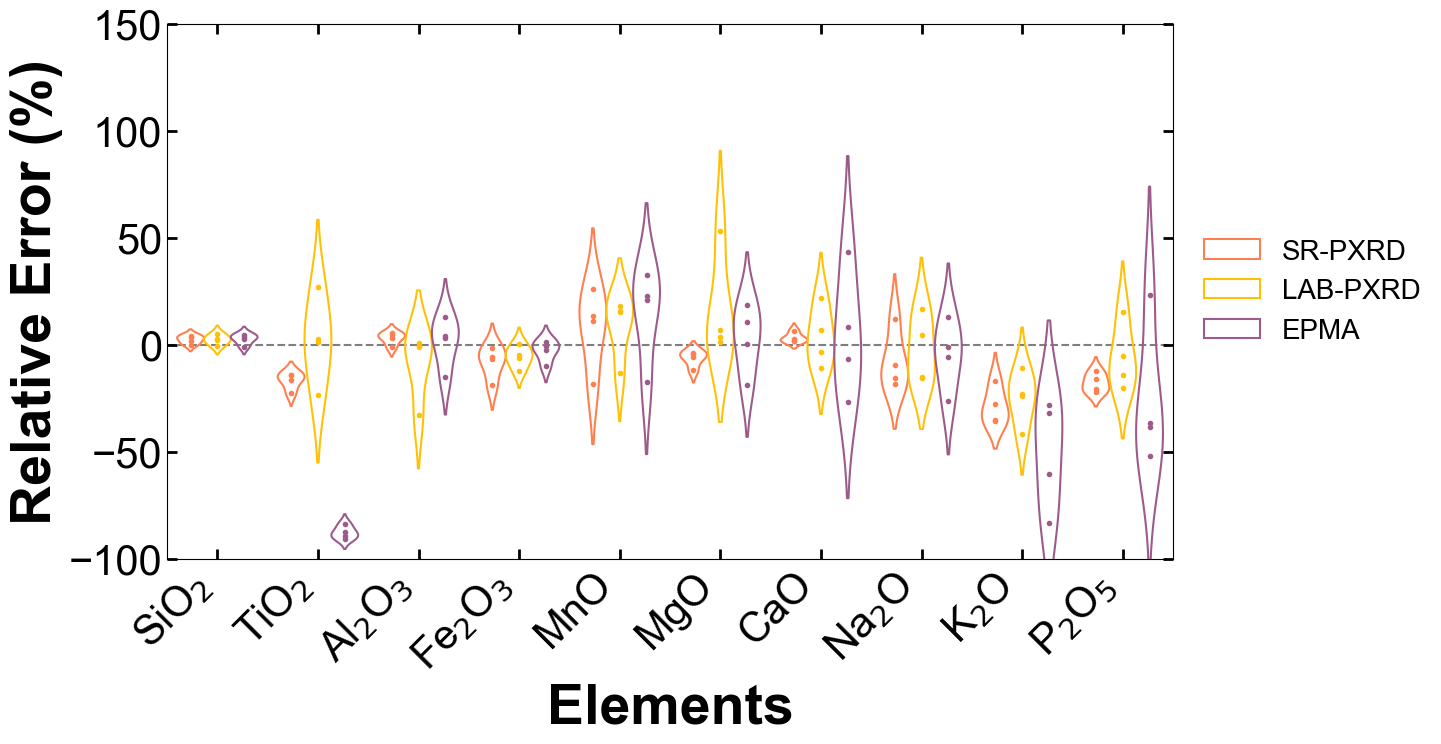

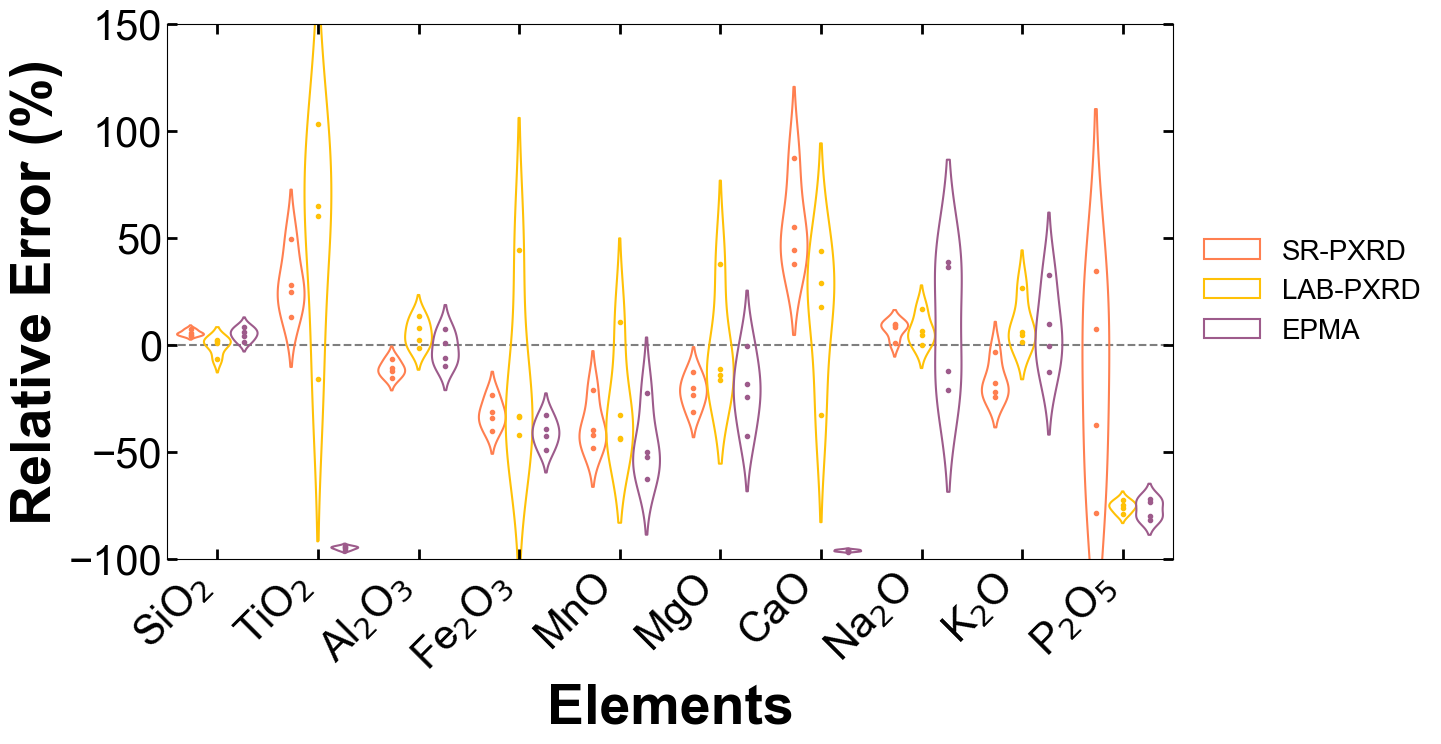

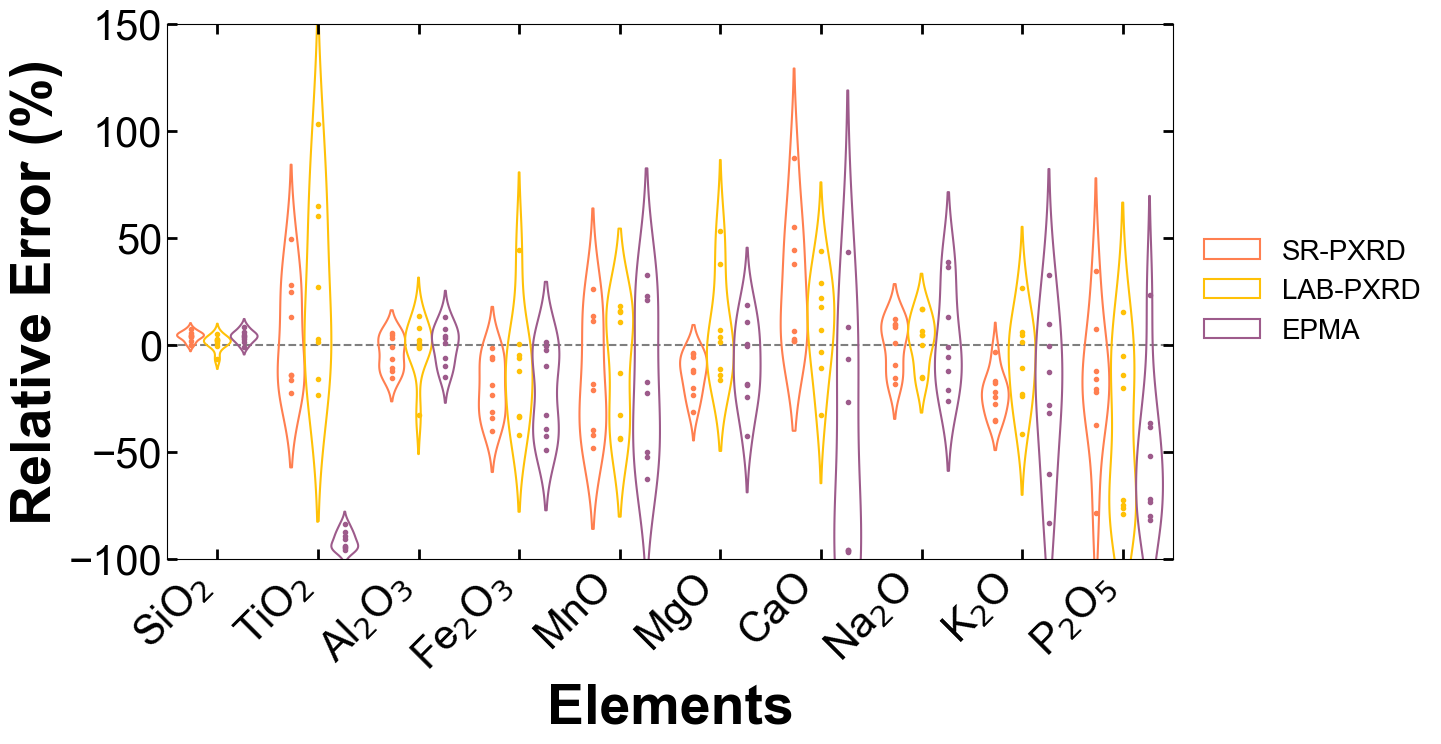

In [3]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(15, 8)) #必要に応じてfigsizeを変更してください
    sns.violinplot(data=data_error_list[num], x="oxides", y="Relative Error100", hue="Instrument", density_norm='width', fill=False, inner="point",\
                   order=list_oxides, palette=Instrument_c_list)
    
    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) # 可視化のために色を赤に、点線にする。
    plt.ylim(-100, 150)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    tick_positions = plt.gca().get_xticks()
    plt.xticks(ticks=tick_positions, labels=latex_oxides)
    plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("Elements", fontsize=40, weight="bold")
    plt.ylabel("Relative Error (%)", fontsize=40, weight="bold")
    plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0, fontsize=20, frameon=False)
    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_violin.pdf', )
    plt.show()


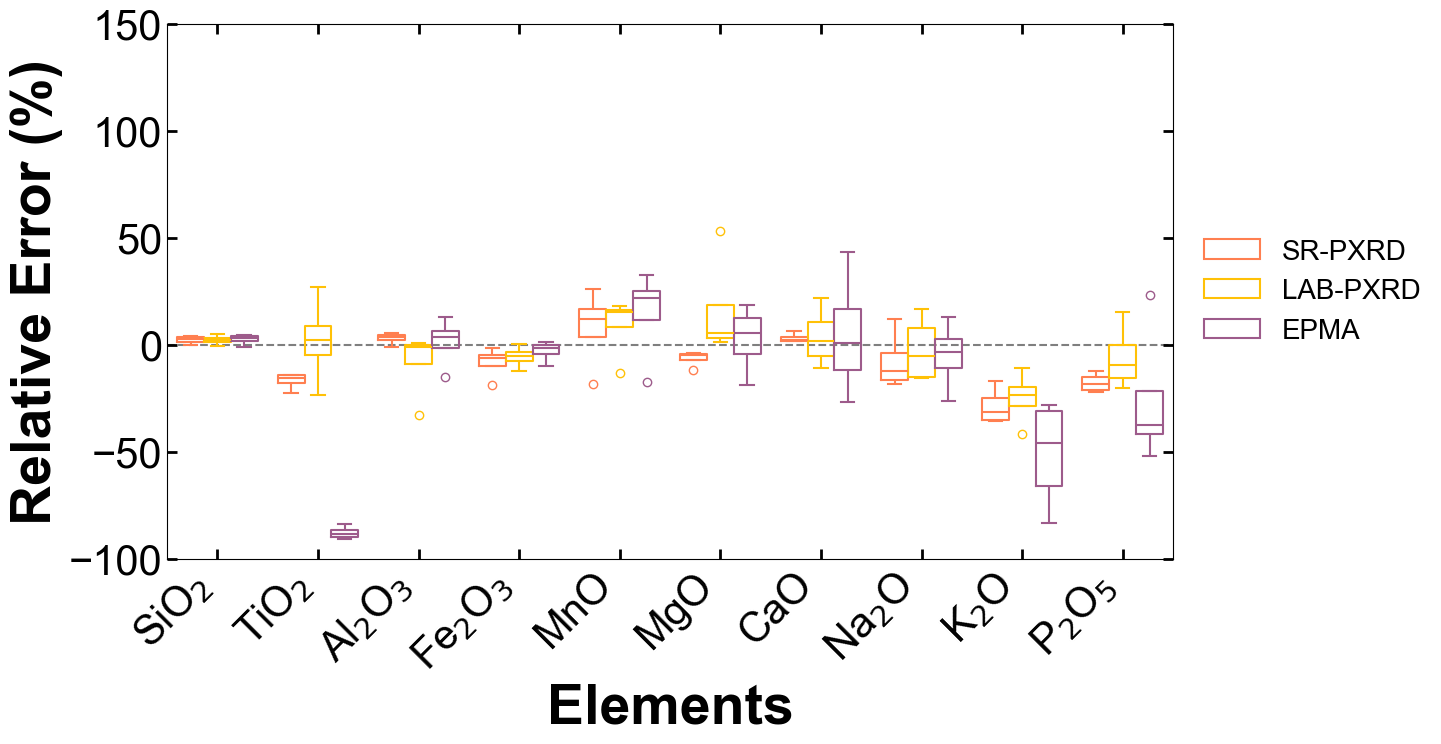

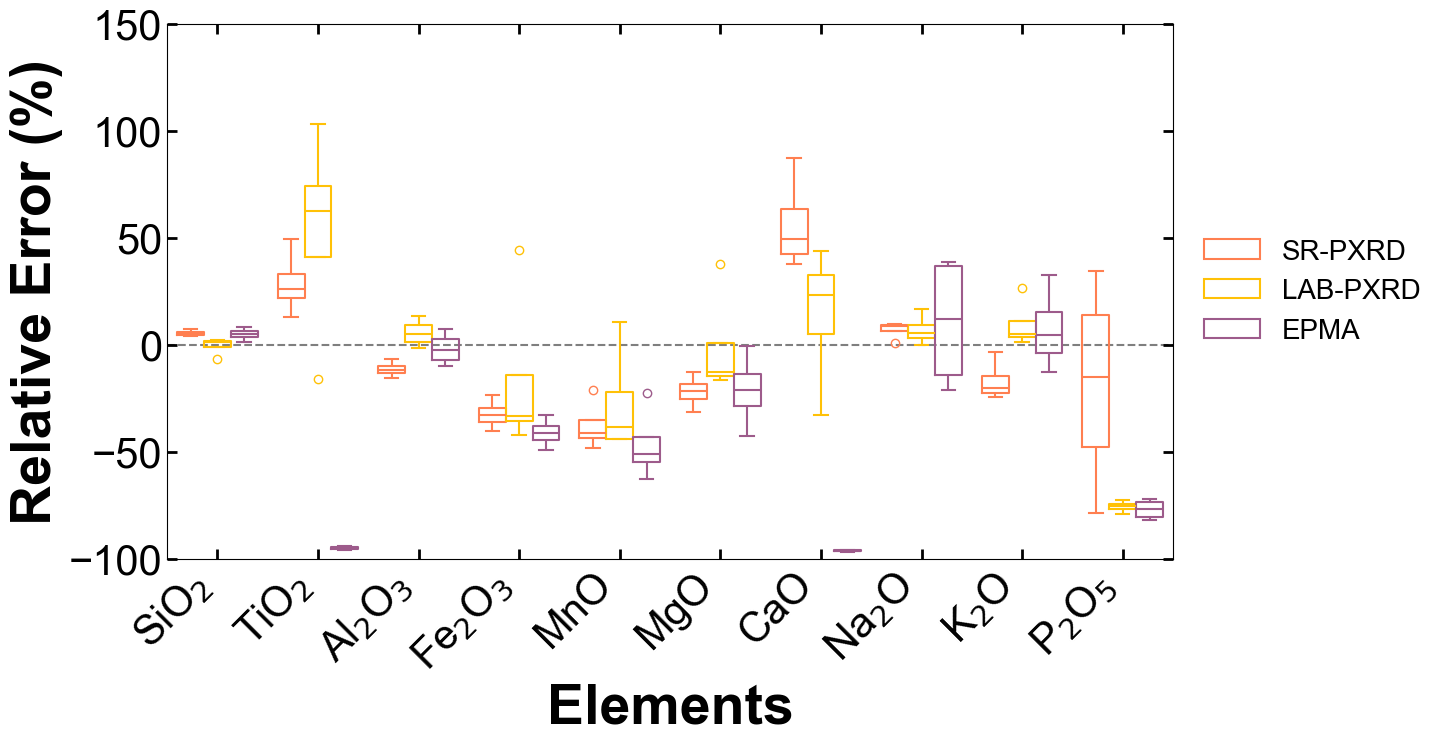

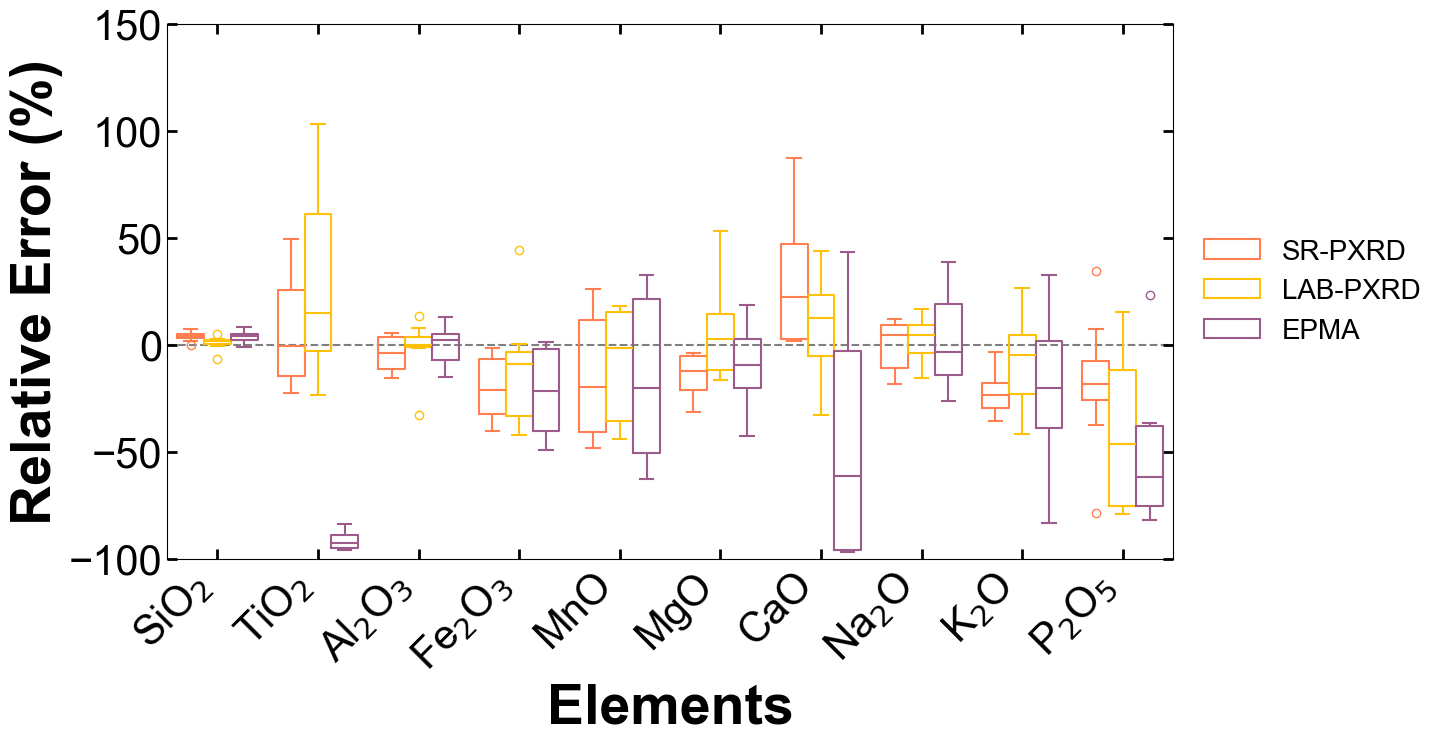

In [4]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(15, 8)) #必要に応じてfigsizeを変更してください
    sns.boxplot(data=data_error_list[num], x="oxides", y="Relative Error100", hue="Instrument", fill=False, order=list_oxides, palette=Instrument_c_list)
    
    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) # 可視化のために色を赤に、点線にする。
    plt.ylim(-100, 150)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    tick_positions = plt.gca().get_xticks()
    plt.xticks(ticks=tick_positions, labels=latex_oxides)
    plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("Elements", fontsize=40, weight="bold")
    plt.ylabel("Relative Error (%)", fontsize=40, weight="bold")
    plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', borderaxespad=0, fontsize=20, frameon=False)
    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_box.pdf', )
    plt.show()


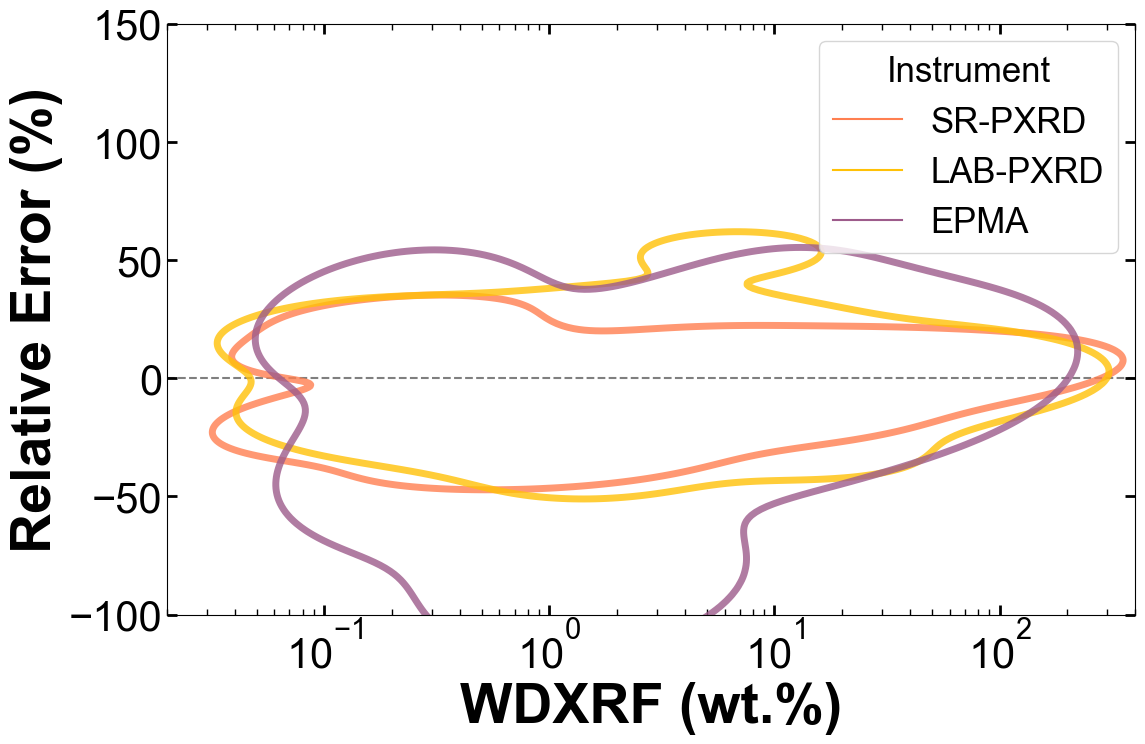

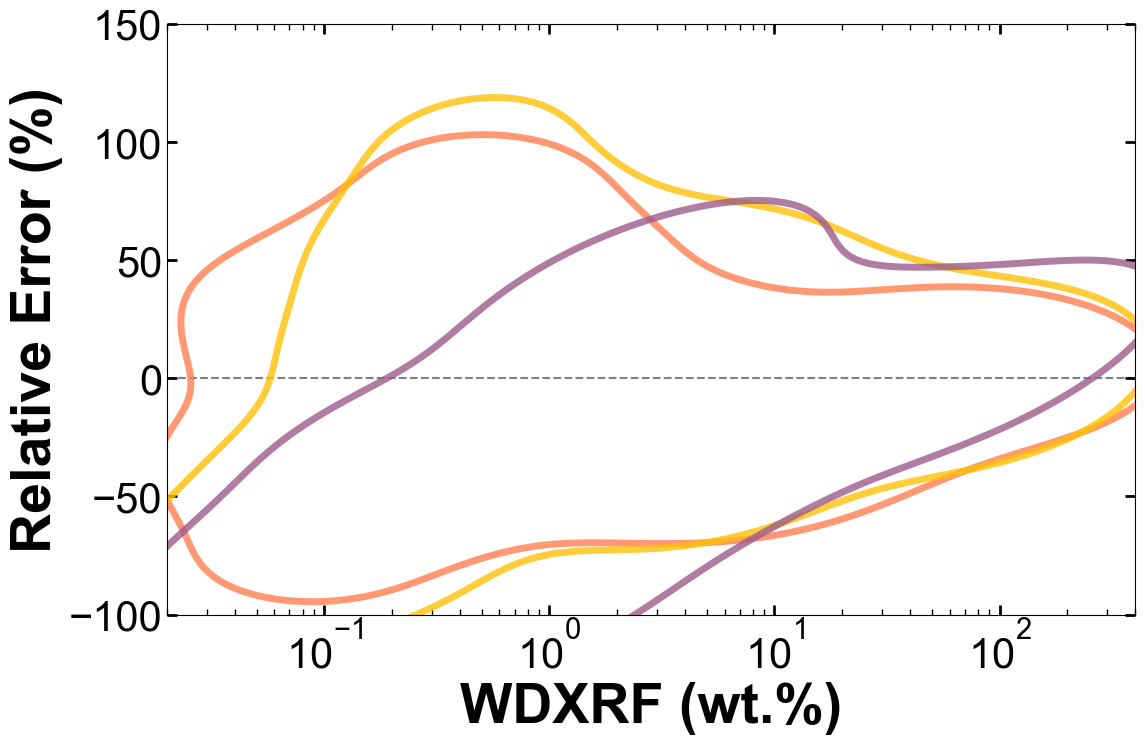

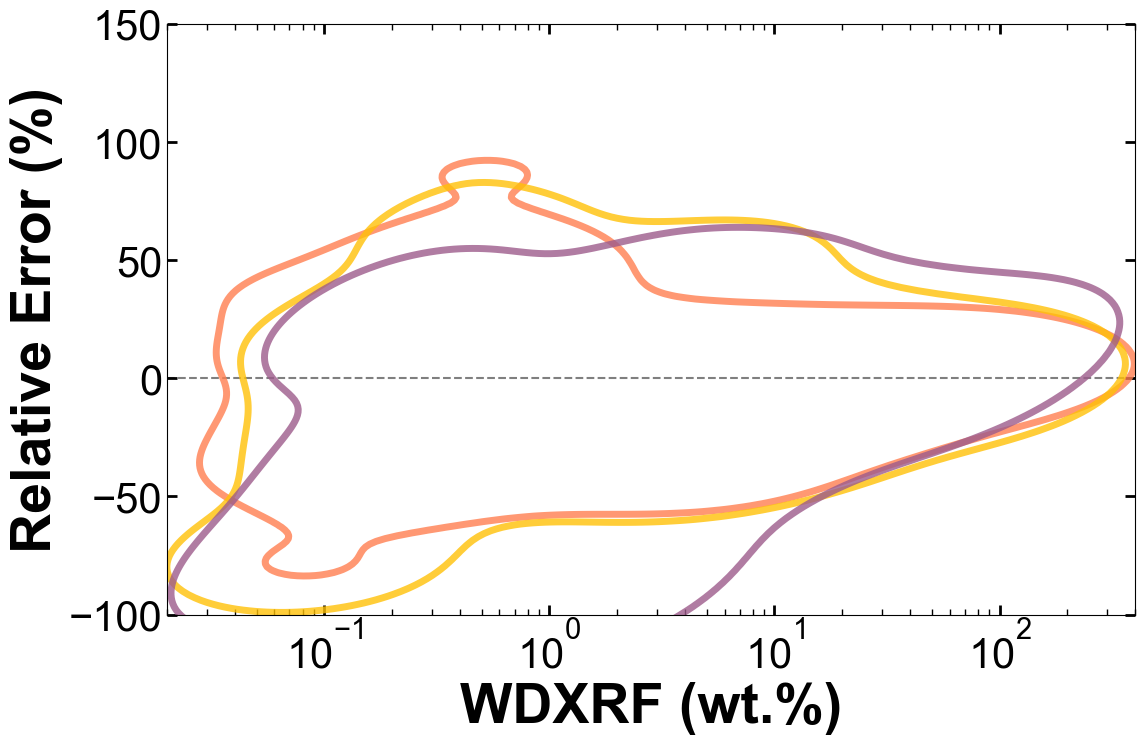

In [5]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(12, 8)) #必要に応じてfigsizeを変更してください
    if num==0:
        legend_flag=True
    else:
        legend_flag=False
    sns.kdeplot(
                data=data_error_list[num], x="XRF", y="Relative Error100", hue="Instrument", hue_order=Instrument_list, 
                levels = 2, linestyles='-', linewidths=5, alpha=0.8,\
                log_scale=[True, False],  fill=False, legend=legend_flag, palette=Instrument_c_list
               )

    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) 
    plt.xlim(0.02, 400)
    plt.ylim(-100, 150)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    #tick_positions = plt.gca().get_xticks()
    #plt.xticks(ticks=tick_positions, labels=latex_oxides)
    #plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("WDXRF (wt.%)", fontsize=40, weight="bold")
    plt.ylabel("Relative Error (%)", fontsize=40, weight="bold")

    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_kde.pdf', )
    plt.show()


/var/folders/h8/5bzln_s513n0w_fc4k78vt9h0000gn/T/ipykernel_46094/42917255.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\


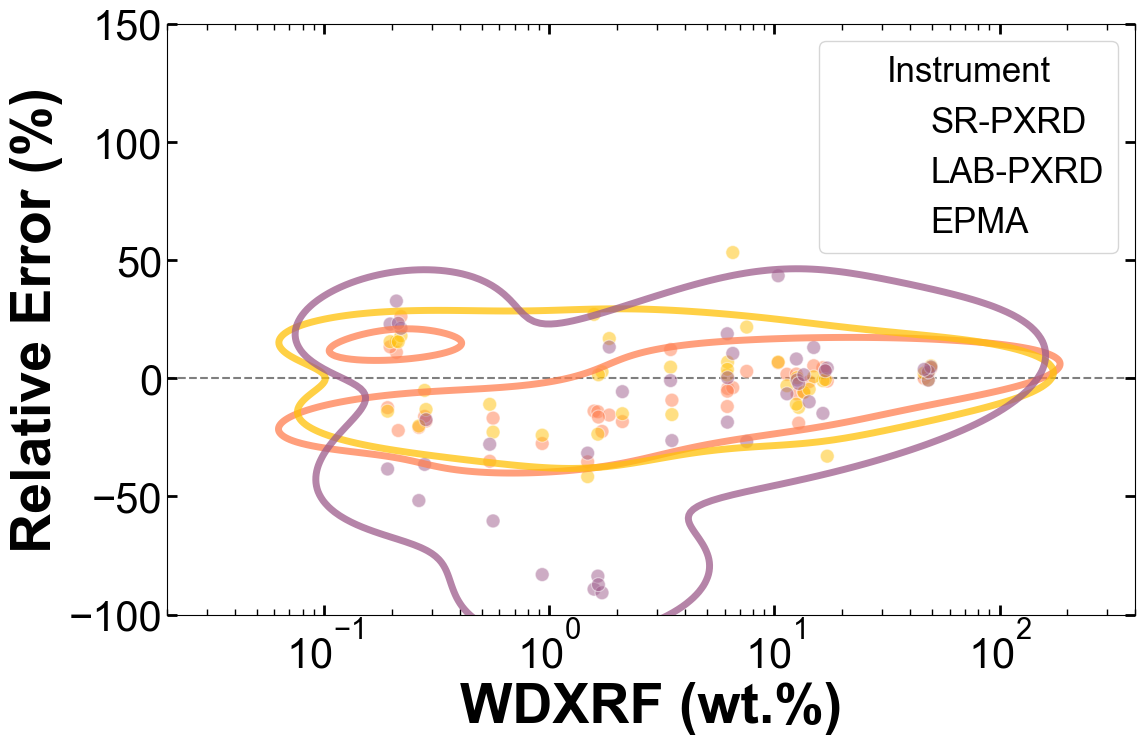

/var/folders/h8/5bzln_s513n0w_fc4k78vt9h0000gn/T/ipykernel_46094/42917255.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\


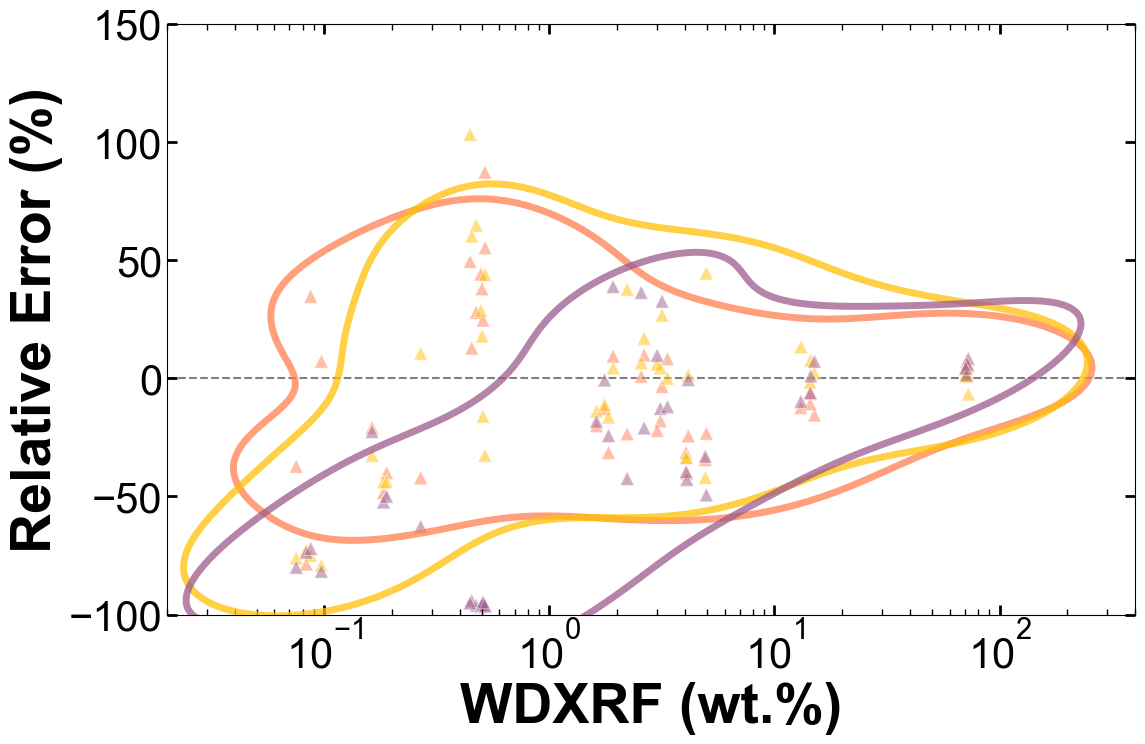

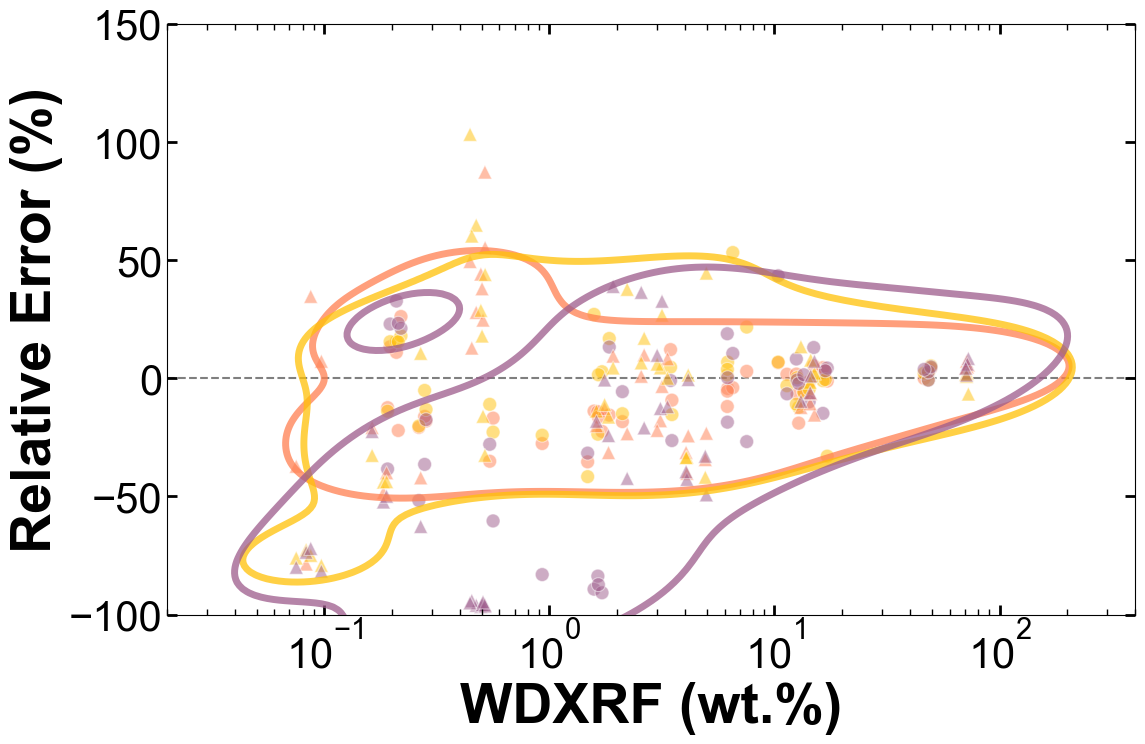

In [6]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(12, 8)) #必要に応じてfigsizeを変更してください
    if num==0:
        legend_flag=True
    else:
        legend_flag=False
    # kdeplot
    sns.kdeplot(
                data=data_error_list[num], x="XRF", y="Relative Error100", hue="Instrument", hue_order=Instrument_list, 
                levels = 1, cut=3, thresh=0.17, linestyles='-', linewidths=5, alpha=0.75,\
                log_scale=[True, False], common_grid=True, common_norm=False, fill=False, legend=legend_flag, palette=Instrument_c_list, zorder=4
               ) 
    # scatterplot
    for rocktype, marker in zip(rocktype_list, rocktype_symbol_list): 
            subset_data = data_error_list[num][data_error_list[num]["Rock type"]==rocktype]
            sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\
                            s=100, alpha=0.5, legend=legend_flag, zorder=1, #marker=marker, # マーカーの順番を明示的に指定
                            marker=marker, hue_order=Instrument_list, palette=Instrument_c_list,\
                            facecolors="none"
                           )
    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) 
    plt.xlim(0.02, 400)
    plt.ylim(-100, 150)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    #tick_positions = plt.gca().get_xticks()
    #plt.xticks(ticks=tick_positions, labels=latex_oxides)
    #plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("WDXRF (wt.%)", fontsize=40, weight="bold")
    plt.ylabel("Relative Error (%)", fontsize=40, weight="bold")

    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_kde_scatter.pdf', )
    plt.show()


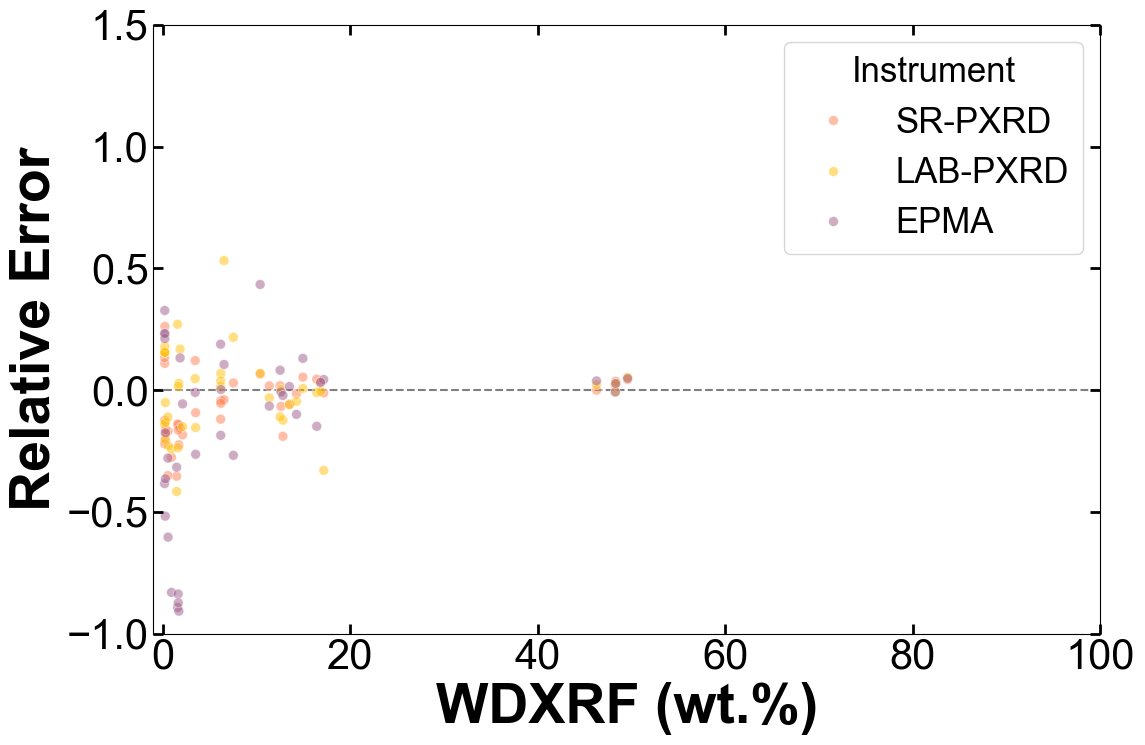

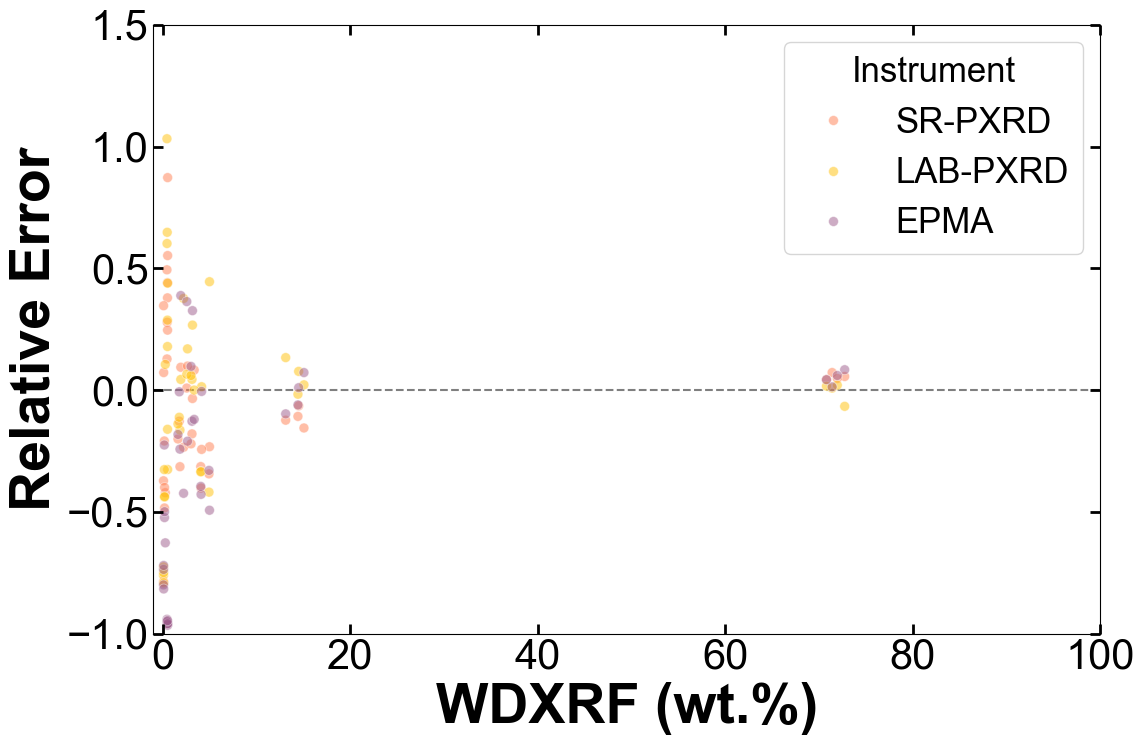

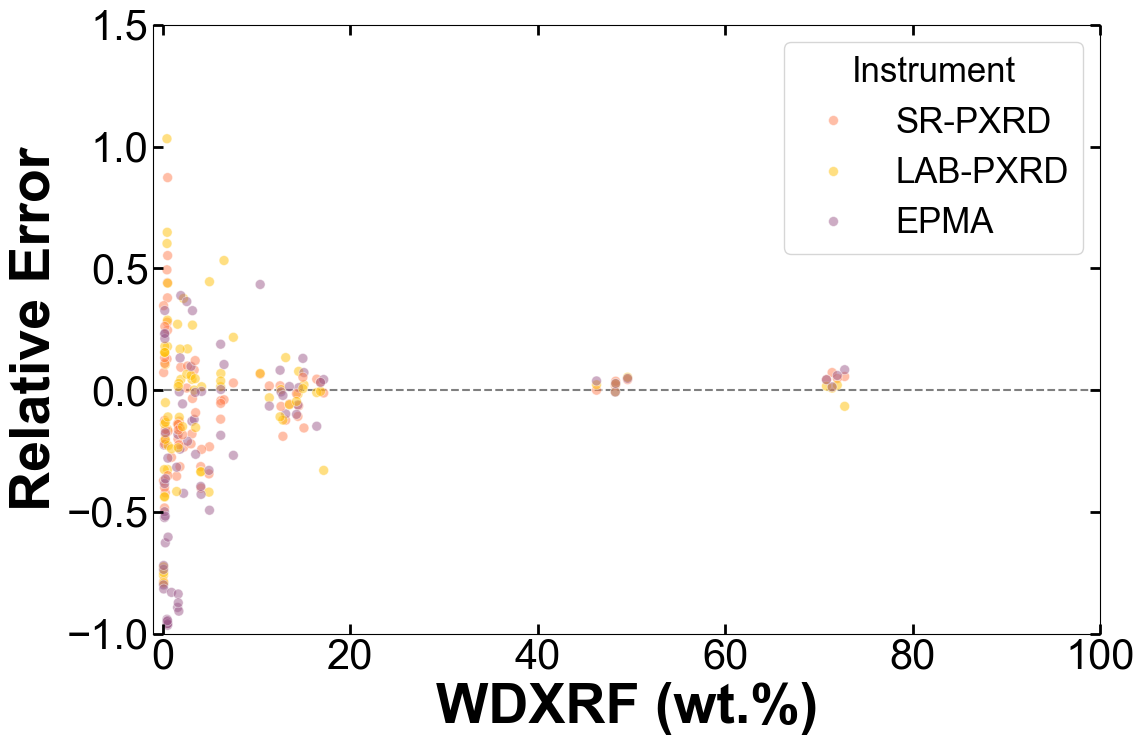

In [7]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(12, 8)) #必要に応じてfigsizeを変更してください
    if num==0:
        legend_flag=True
    else:
        legend_flag=False

    sns.scatterplot(data=data_error_list[num], x="XRF", y="Relative Error", hue="Instrument",\
                    hue_order=Instrument_list, palette=Instrument_c_list, s=50, alpha=0.5, )

    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) 
    plt.xlim(-1, 100)
    plt.ylim(-1, 1.5)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    #tick_positions = plt.gca().get_xticks()
    #plt.xticks(ticks=tick_positions, labels=latex_oxides)
    #plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("WDXRF (wt.%)", fontsize=40, weight="bold")
    plt.ylabel("Relative Error", fontsize=40, weight="bold")

    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_kde_scatter.pdf', )
    plt.show()


/var/folders/h8/5bzln_s513n0w_fc4k78vt9h0000gn/T/ipykernel_46094/861382873.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\


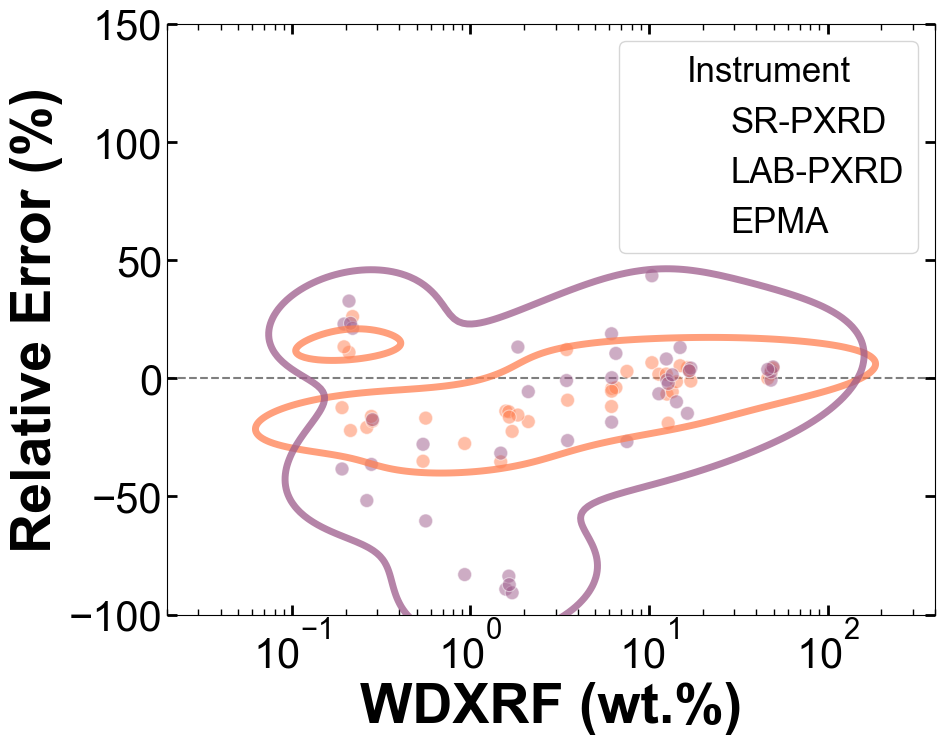

/var/folders/h8/5bzln_s513n0w_fc4k78vt9h0000gn/T/ipykernel_46094/861382873.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\


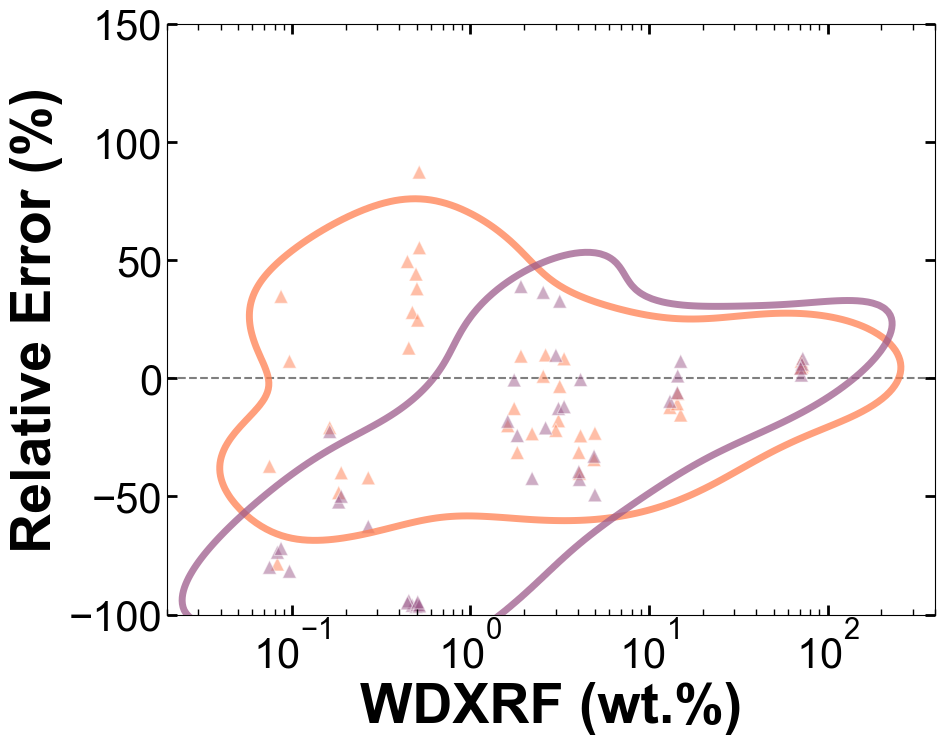

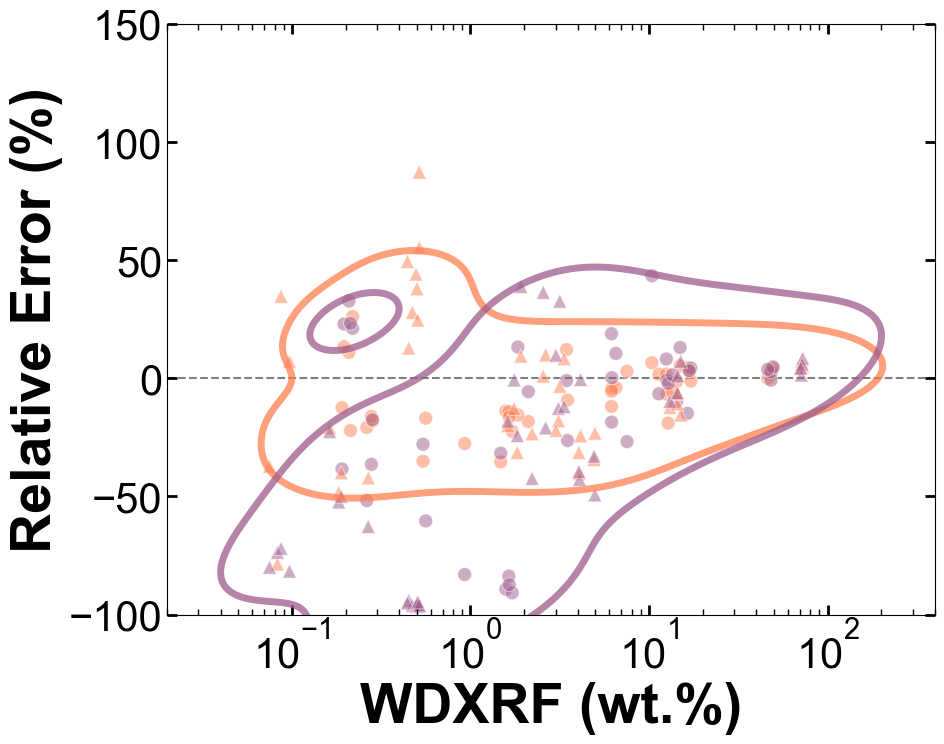

In [8]:
for num, (name, color) in enumerate(zip(data_name_list, Instrument_c_list)):
    # バイオリンプロット
    plt.figure(figsize=(10, 8)) #必要に応じてfigsizeを変更してください
    if num==0:
        legend_flag=True
    else:
        legend_flag=False
    # kdeplot
    sns.kdeplot(
                data=data_error_list[num][data_error_list[num]["Instrument"]!="LAB-PXRD"], x="XRF", y="Relative Error100", hue="Instrument", hue_order=Instrument_list, 
                levels = 1, cut=3, thresh=0.17, linestyles='-', linewidths=5, alpha=0.75,\
                log_scale=[True, False], common_grid=True, common_norm=False, fill=False, legend=legend_flag, palette=Instrument_c_list, zorder=4
               ) 
    # scatterplot
    for rocktype, marker in zip(rocktype_list, rocktype_symbol_list): 
            subset_data = data_error_list[num][(data_error_list[num]["Rock type"]==rocktype)&(data_error_list[num]["Instrument"]!="LAB-PXRD")]
            sns.scatterplot(data=subset_data, x="XRF", y="Relative Error100", hue="Instrument",\
                            s=100, alpha=0.5, legend=legend_flag, zorder=1, #marker=marker, # マーカーの順番を明示的に指定
                            marker=marker, hue_order=Instrument_list, palette=Instrument_c_list,\
                            facecolors="none"
                           )
    # 水平線を追加
    plt.axhline(y=0, color='black', linestyle='--', zorder=0, alpha=0.5) 
    plt.xlim(0.02, 400)
    plt.ylim(-100, 150)
    
    ################ 調整
    plt.tick_params(which='both', direction='in', bottom=True, left=True, top=True, right=True, labelsize=30)
    plt.tick_params(which='major', length=7.5, width=2)
    plt.tick_params(which='minor', length=4, width=1)
    # 目盛りの位置を取得
    #tick_positions = plt.gca().get_xticks()
    #plt.xticks(ticks=tick_positions, labels=latex_oxides)
    #plt.xticks(rotation=45, ha="right")
    
    # label
    plt.xlabel("WDXRF (wt.%)", fontsize=40, weight="bold")
    plt.ylabel("Relative Error (%)", fontsize=40, weight="bold")

    ################ 調整
    
    plt.tight_layout() # レイアウト調整
    # ファイル保存
    plt.savefig(relative_error_dir / f'{name}_Relative_Error_kde_scatter_without_LAB.pdf', )
    plt.show()
